<a href="https://colab.research.google.com/github/kamalika1191-cloud/bias-audit-mlops/blob/main/notebooks/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Data exploration: Bias in Bios
**Capstone:** An MLOps Pipeline for Continuous Bias Auditing of AI Résumé Screening  
**Goal of this notebook:** load the real Bias in Bios data, understand its structure, and see how gender is distributed across the 28 occupations.

Run each cell from top to bottom with **Shift + Enter**.

## 1. Load the dataset
The data comes from Hugging Face (`LabHC/bias_in_bios`, MIT license). It has three columns: `hard_text` (the biography), `profession` (0–27) and `gender` (0 = male, 1 = female).

In [1]:
!pip install -q datasets

from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt

ds = load_dataset("LabHC/bias_in_bios")
print(ds)

README.md:   0%|          | 0.00/3.30k [00:00<?, ?B/s]

data/train-00000-of-00001-0ab65b32c47407(…): reconstructing file:   0%|          |  0.00B / 64.9MB            

data/train-00000-of-00001-0ab65b32c47407(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-5598c840ce8de1e(…): reconstructing file:   0%|          |  0.00B / 24.9MB            

data/test-00000-of-00001-5598c840ce8de1e(…): downloading bytes:           |  0.00B            

data/dev-00000-of-00001-e6551072fff26949(…): reconstructing file:   0%|          |  0.00B / 9.95MB            

data/dev-00000-of-00001-e6551072fff26949(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/257478 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/99069 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/39642 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['hard_text', 'profession', 'gender'],
        num_rows: 257478
    })
    test: Dataset({
        features: ['hard_text', 'profession', 'gender'],
        num_rows: 99069
    })
    dev: Dataset({
        features: ['hard_text', 'profession', 'gender'],
        num_rows: 39642
    })
})


## 2. Turn it into tables and add readable labels

In [2]:
PROFESSIONS = ["accountant", "architect", "attorney", "chiropractor", "comedian", "composer",
               "dentist", "dietitian", "dj", "filmmaker", "interior_designer", "journalist",
               "model", "nurse", "painter", "paralegal", "pastor", "personal_trainer",
               "photographer", "physician", "poet", "professor", "psychologist", "rapper",
               "software_engineer", "surgeon", "teacher", "yoga_teacher"]
GENDERS = {0: "male", 1: "female"}

def to_df(split):
    df = ds[split].to_pandas()
    df["profession_name"] = df["profession"].map(lambda i: PROFESSIONS[i])
    df["gender_name"] = df["gender"].map(GENDERS)
    return df

train, dev, test = to_df("train"), to_df("dev"), to_df("test")
print(f"train: {len(train):,}   dev: {len(dev):,}   test: {len(test):,}")
train.head()

train: 257,478   dev: 39,642   test: 99,069


,hard_text,profession,gender,profession_name,gender_name
0,He is also the project lead of and major contr...,21,0,professor,male
1,"She is able to assess, diagnose and treat mino...",13,1,nurse,female
2,"Prior to law school, Brittni graduated magna c...",2,1,attorney,female
3,He regularly contributes to India’s First Onli...,11,0,journalist,male
4,He completed his medical degree at Northwester...,21,0,professor,male


## 3. Read one real example

In [3]:
example = train.iloc[0]
print("Profession:", example["profession_name"], "| Gender:", example["gender_name"])
print()
print(example["hard_text"])

Profession: professor | Gender: male

He is also the project lead of and major contributor to the open source assembler/simulator "EASy68K." He earned a master’s degree in computer science from the University of Michigan-Dearborn, where he is also an adjunct instructor. Downloads/Updates


## 4. Data quality checks
Missing values and duplicates can distort results later, so check them now.

In [4]:
print("Missing values:\n", train.isna().sum())
print("\nDuplicate biographies in train:", train["hard_text"].duplicated().sum())
print("\nGender split (whole train set):")
print(train["gender_name"].value_counts(normalize=True).round(3))

Missing values:
 hard_text          0
profession         0
gender             0
profession_name    0
gender_name        0
dtype: int64

Duplicate biographies in train: 382

Gender split (whole train set):
gender_name
male      0.539
female    0.461
Name: proportion, dtype: float64


## 5. How many biographies per occupation?
Some jobs have many more examples than others. Small groups give less reliable bias numbers later.

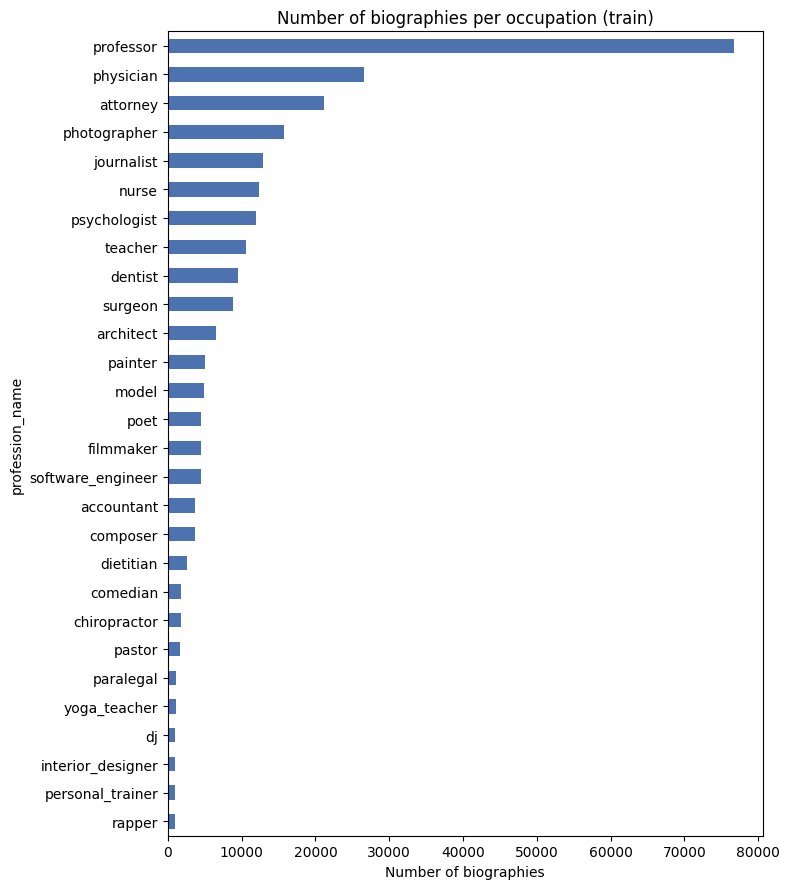

In [5]:
counts = train["profession_name"].value_counts().sort_values()

plt.figure(figsize=(8, 9))
counts.plot(kind="barh", color="#4C72B0")
plt.title("Number of biographies per occupation (train)")
plt.xlabel("Number of biographies")
plt.tight_layout()
plt.savefig("bios_per_occupation.png", dpi=150)
plt.show()

## 6. Share of women in each occupation
This is the key chart. Strong imbalances (for example nurse vs. surgeon) are where screening models are most likely to learn gender bias. Red = under 30% women, green = over 70%.

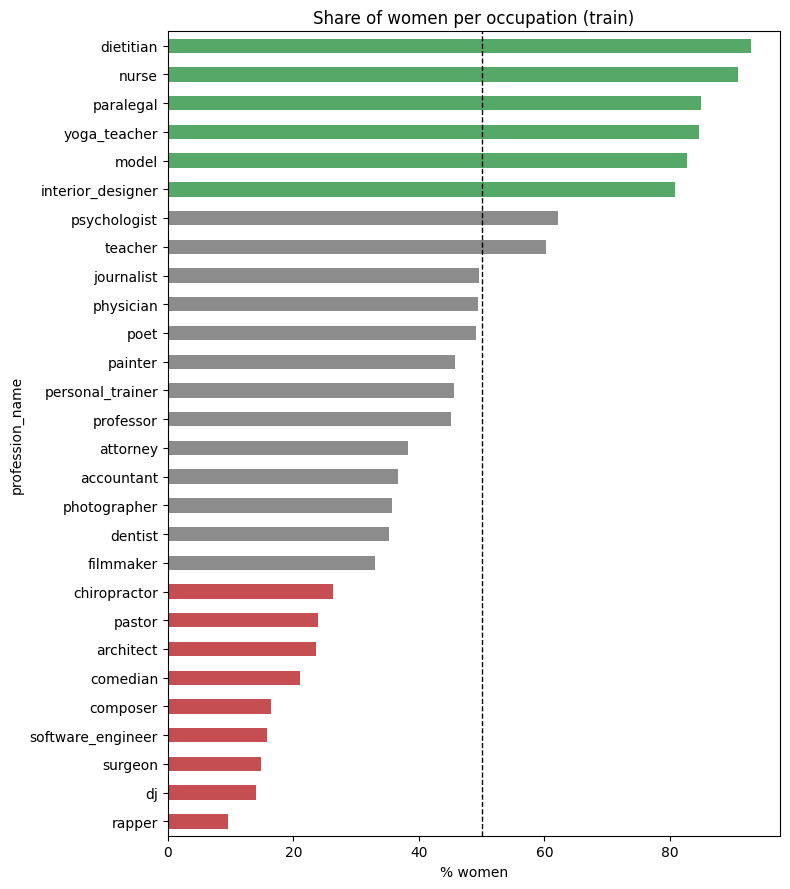

Most male-dominated:
 profession_name
rapper                9.7
dj                   14.1
surgeon              14.8
software_engineer    15.8
composer             16.4
Name: gender, dtype: float64

Most female-dominated:
 profession_name
model           82.7
yoga_teacher    84.6
paralegal       84.9
nurse           90.8
dietitian       92.9
Name: gender, dtype: float64


In [6]:
share_female = (train.groupby("profession_name")["gender"].mean() * 100).sort_values()

plt.figure(figsize=(8, 9))
colors = ["#C44E52" if v < 30 else "#55A868" if v > 70 else "#8C8C8C" for v in share_female]
share_female.plot(kind="barh", color=colors)
plt.axvline(50, color="black", linestyle="--", linewidth=1)
plt.title("Share of women per occupation (train)")
plt.xlabel("% women")
plt.tight_layout()
plt.savefig("share_women_per_occupation.png", dpi=150)
plt.show()

print("Most male-dominated:\n", share_female.head(5).round(1))
print("\nMost female-dominated:\n", share_female.tail(5).round(1))

## 7. Biography length
Useful later for choosing models: LLMs have input limits, and very short bios carry little information.

count    257478.0
mean         60.7
std          28.5
min          10.0
25%          37.0
50%          55.0
75%          79.0
max         179.0
Name: n_words, dtype: float64


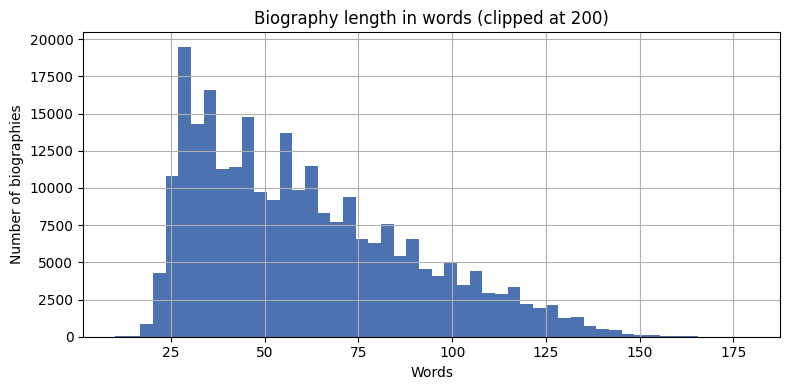

In [7]:
train["n_words"] = train["hard_text"].str.split().str.len()
print(train["n_words"].describe().round(1))

plt.figure(figsize=(8, 4))
train["n_words"].clip(upper=200).hist(bins=50, color="#4C72B0")
plt.title("Biography length in words (clipped at 200)")
plt.xlabel("Words")
plt.ylabel("Number of biographies")
plt.tight_layout()
plt.savefig("bio_length.png", dpi=150)
plt.show()

## 8. Save a summary table
This table goes into progress report 2 and is reused in later notebooks.

In [8]:
summary = pd.DataFrame({
    "n_bios": counts,
    "pct_women": share_female.round(1),
}).sort_values("pct_women")
summary.to_csv("occupation_summary.csv")
summary

,n_bios,pct_women
profession_name,,
rapper,911,9.7
dj,964,14.1
surgeon,8829,14.8
software_engineer,4492,15.8
composer,3637,16.4
comedian,1824,21.1
architect,6568,23.7
pastor,1638,24.0
chiropractor,1725,26.3


## 9. What I found
The dataset has 257,478 training, 39,642 dev and 99,069 test biographies across 28 occupations. There are no missing values, and only 382 duplicate biographies (about 0.15% of the training set), so the data is clean.

Overall, 46.1% of the biographies are about women and 53.9% about men. But individual occupations are strongly imbalanced: only 9.7% of rappers, 14.1% of DJs, 14.8% of surgeons and 15.8% of software engineers are women, while 90.8% of nurses and 92.9% of dietitians are women.

Because the data reflects these imbalances, a screening model may learn to link some jobs with one gender. For example, it might recognise female surgeons less often than male surgeons, or male nurses less often than female nurses. I will measure this with the TPR gap in the next notebook.